# بيانات عن مرض القلب

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# تحميل المكتبات والداتا

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df = pd.read_csv('heart.csv')

# فهم الداتا

In [6]:
# الحجم وأسماء الأعمدة
print("Size:", df.shape)
print("Features:", df.columns.tolist())

# القيم الناقصة
print("Missing Values:\n", df.isnull().sum())

# توزيع الـ target
print("Target:\n", df['HeartDisease'].value_counts())

# إحصائيات عامة
df.describe()

Size: (918, 12)
Features: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']
Missing Values:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Target:
 HeartDisease
1    508
0    410
Name: count, dtype: int64


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


# تعريف المشكله

In [7]:
# هذي مشكلة Classification
# لأن الـ target (HeartDisease) قيمتين بس: 0 أو 1
print("Problem Type: Binary Classification")
print("Target column: HeartDisease (0 = No Disease, 1 = Disease)")

Problem Type: Binary Classification
Target column: HeartDisease (0 = No Disease, 1 = Disease)


# تصاويرEDA

/tmp/ipykernel_2172/1809371984.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HeartDisease', data=df, palette='Set2')


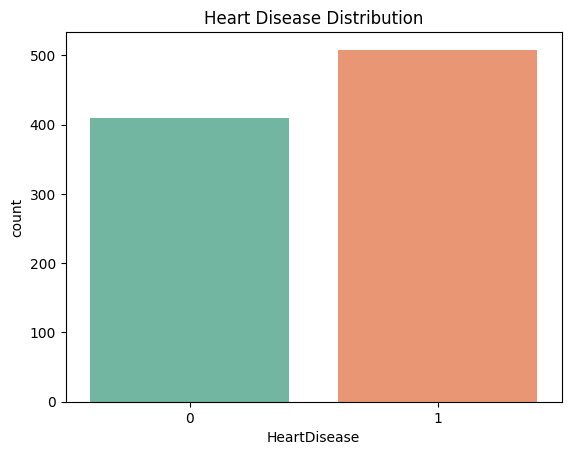

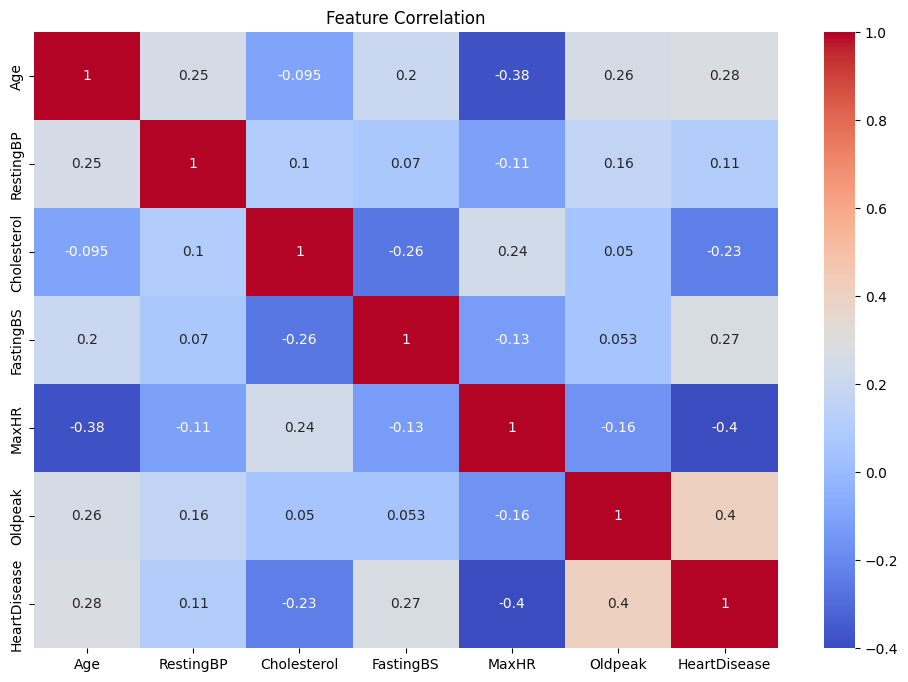

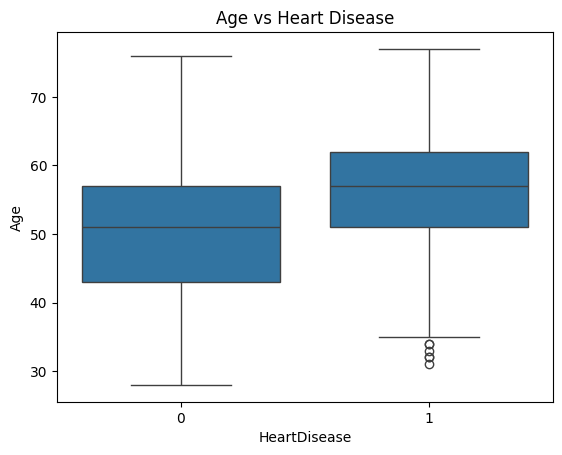

In [8]:
# توزيع المرض
sns.countplot(x='HeartDisease', data=df, palette='Set2')
plt.title('Heart Disease Distribution')
plt.show()

# العلاقة بين المتغيرات
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Feature Correlation')
plt.show()

# العمر والمرض
sns.boxplot(x='HeartDisease', y='Age', data=df)
plt.title('Age vs Heart Disease')
plt.show()

# تنظيف وتجهيز الداتا

In [9]:
# تحويل الأعمدة النصية لأرقام
df = pd.get_dummies(df, drop_first=True)

# تقسيم Features و Target
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

# تقسيم الداتا 80% تدريب و 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# تعديل Scale الأرقام
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# تدريب النموذجين

In [10]:
# النموذج الأول: Logistic Regression
# اخترناه لأنه بسيط وسريع ومناسب للـ Binary Classification
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# النموذج الثاني: Random Forest
# اخترناه لأنه أقوى ويقدر يكشف علاقات معقدة في الداتا
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

# التقيم و المقارنه


--- Logistic Regression ---
Accuracy: 0.8533
F1 Score: 0.8696
              precision    recall  f1-score   support

           0       0.80      0.87      0.83        77
           1       0.90      0.84      0.87       107

    accuracy                           0.85       184
   macro avg       0.85      0.86      0.85       184
weighted avg       0.86      0.85      0.85       184


--- Random Forest ---
Accuracy: 0.875
F1 Score: 0.892
              precision    recall  f1-score   support

           0       0.85      0.86      0.85        77
           1       0.90      0.89      0.89       107

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



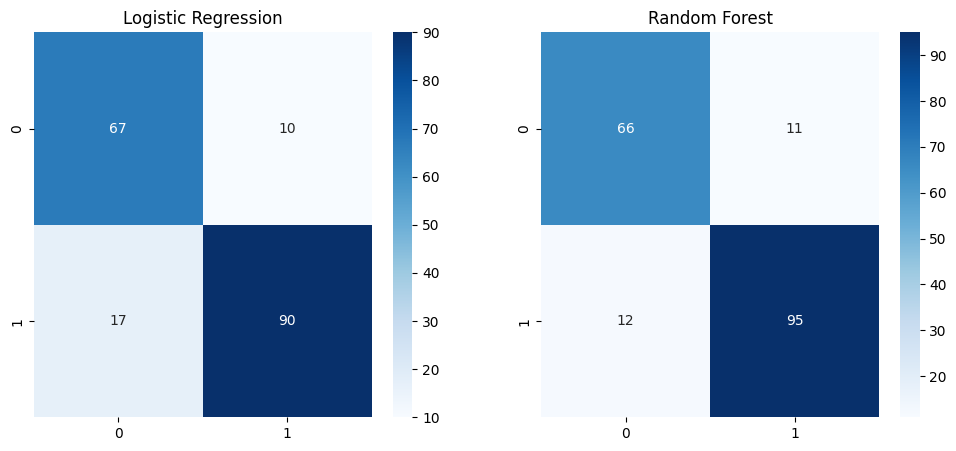

In [11]:
for name, model in [('Logistic Regression', lr), ('Random Forest', rf)]:
    y_pred = model.predict(X_test)
    print(f"\n--- {name} ---")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1 Score:", round(f1_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred))

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, model, name in zip(axes, [lr, rf], ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
plt.show()

# تفسير النتايج

/tmp/ipykernel_2172/2265777365.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


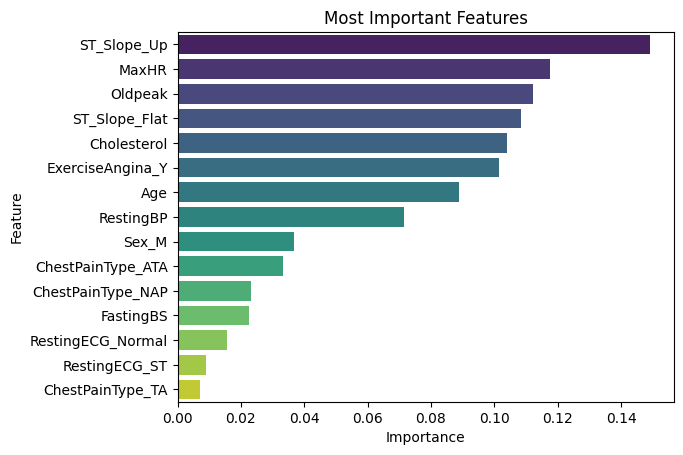

Best Model: Random Forest


In [12]:
# Feature Importance — أهم المتغيرات في التنبؤ
feat_df = pd.DataFrame({
    'Feature': df.drop('HeartDisease', axis=1).columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title('Most Important Features')
plt.show()

print("Best Model: Random Forest" if
      f1_score(y_test, rf.predict(X_test)) > f1_score(y_test, lr.predict(X_test))
      else "Best Model: Logistic Regression")